# Hackathon 2 — Job Market Intelligence

## Objective and research questions
Analyze a convenience sample of **10,000 historical 2023 job postings** to identify frequently requested technical skills, differences between Data Analyst / Data Engineer / Data Scientist roles, geographic patterns, remote-work indicators, and reported salaries. Use a separate Kaggle salary dataset to test whether job characteristics help predict annual salary.

## Data sources and scope
| Source | Use | Important caveat |
|---|---|---|
| [Hugging Face: lukebarousse/data_jobs](https://huggingface.co/datasets/lukebarousse/data_jobs) | First 10,000 records; historical job-market EDA | Convenience slice, not a random or representative sample; historical 2023 postings |
| [Remotive remote-jobs API](https://remotive.com/api/remote-jobs) | Optional snapshot of currently returned remote listings | Different population from historical data; availability and number of listings vary |
| [Kaggle: Data Science Salaries 2023](https://www.kaggle.com/datasets/arnabchaki/data-science-salaries-2023) | Salary-prediction demonstration | Separate dataset; no verified job-level link to Hugging Face data |

**Research questions:** Which technical skills appear most often? How do skill requirements differ by role? What patterns appear in location, remote-work flags, and reported salary? Can job characteristics predict salary more accurately than a simple baseline?

**Method:** Inspect and clean each dataset separately, summarize patterns, train a baseline and a Random Forest regression model, and evaluate on held-out data. These observational findings do not establish causation.

## Install and Import Libraries

In [1]:

!pip -q install datasets openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [6]:
import ast
import re
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 1. Load data ---
print("Loading dataset...")
dataset = load_dataset("lukebarousse/data_jobs", split="train", streaming=True)
sample = list(dataset.take(10000))
df = pd.DataFrame(sample)

# --- 2. Clean Historical Data ---
print("Cleaning historical data...")
df_clean = df.copy()
df_clean["job_posted_date"] = pd.to_datetime(df_clean["job_posted_date"], errors="coerce")
for col in ["salary_year_avg", "salary_hour_avg"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
for col in ["job_location", "job_country", "job_schedule_type", "job_via"]:
    df_clean[col] = df_clean[col].fillna("Unknown")
df_clean = df_clean.drop_duplicates().copy()
df_clean["has_annual_salary"] = df_clean["salary_year_avg"].notna()

# --- 3. Extract Skills ---
print("Extracting skills...")
def parse_skills(value):
    if isinstance(value, list): return value
    if pd.isna(value): return []
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list): return parsed
        except (ValueError, SyntaxError): pass
    return []
df_clean["skills_list"] = df_clean["job_skills"].apply(parse_skills)

skill_rows = df_clean.reset_index(drop=True).reset_index(names="job_id")[["job_id", "skills_list"]].explode("skills_list")
skill_rows = skill_rows.dropna(subset=["skills_list"])
skill_rows["skills_list"] = skill_rows["skills_list"].astype(str).str.strip().str.lower()
skill_rows = skill_rows[skill_rows["skills_list"] != ""].drop_duplicates(["job_id", "skills_list"])
skill_counts = skill_rows["skills_list"].value_counts().rename_axis("Skill").reset_index(name="Job Count")

# --- 4. Role Analysis ---
print("Analyzing roles...")
selected_jobs = ["Data Analyst", "Data Engineer", "Data Scientist"]
df_roles = df_clean[df_clean["job_title_short"].isin(selected_jobs)].copy()
roles_with_id = df_roles.reset_index(drop=True).reset_index(names="job_id")
skills_by_role = roles_with_id[["job_id", "job_title_short", "skills_list"]].explode("skills_list").dropna(subset=["skills_list"])
skills_by_role["skills_list"] = skills_by_role["skills_list"].astype(str).str.strip().str.lower()
skills_by_role = skills_by_role[skills_by_role["skills_list"] != ""].drop_duplicates(["job_id", "skills_list"])
role_totals = roles_with_id[roles_with_id["skills_list"].apply(len).gt(0)].groupby("job_title_short").size()
skill_role_counts = skills_by_role.groupby(["job_title_short", "skills_list"]).size().reset_index(name="count")
skill_role_counts["percentage"] = (skill_role_counts["count"] / skill_role_counts["job_title_short"].map(role_totals) * 100)

# --- 5. Geography & Remote ---
remote_by_role = df_clean.groupby("job_title_short")["job_work_from_home"].agg(total_jobs="count", remote_jobs="sum", remote_percentage="mean").reset_index()
remote_by_role["remote_percentage"] *= 100
salary_reporting = df_clean.groupby("job_country").agg(total_jobs=("salary_year_avg", "size"), jobs_with_salary=("salary_year_avg", "count"))
salary_reporting["reporting_rate"] = (salary_reporting["jobs_with_salary"] / salary_reporting["total_jobs"] * 100)

df_us_salary = df_clean[(df_clean["job_country"] == "United States") & (df_clean["salary_year_avg"].notna()) & (df_clean["salary_year_avg"] > 0)].copy()
us_salary_summary = df_us_salary.groupby("job_title_short").agg(median_salary=("salary_year_avg", "median"), mean_salary=("salary_year_avg", "mean"), job_count=("salary_year_avg", "count")).reset_index()

# --- 6. Live API snapshot ---
print("Fetching live API snapshot...")
try:
    response = requests.get("https://remotive.com/api/remote-jobs", params={"limit": 100}, timeout=30)
    response.raise_for_status()
    jobs = response.json().get("jobs", [])
except Exception as exc:
    print("Remotive API unavailable:", exc)
    jobs = []
df_live = pd.DataFrame(jobs)
for col in ["id", "title", "company_name", "candidate_required_location", "publication_date", "description"]:
    if col not in df_live.columns: df_live[col] = pd.Series(dtype="object")
if not df_live.empty:
    df_live["description_clean"] = df_live["description"].apply(lambda x: BeautifulSoup(str(x), "html.parser").get_text(" ", strip=True) if pd.notna(x) else "")
    df_live["publication_date"] = pd.to_datetime(df_live["publication_date"], errors="coerce", utc=True)
    df_live = df_live.drop_duplicates(subset=["id"]).copy()
    skills_to_find = ["python", "sql", "excel", "tableau", "power bi", "aws", "azure", "spark", "snowflake", "r", "pandas", "numpy"]
    df_live["extracted_skills"] = df_live["description_clean"].apply(lambda text: [s for s in skills_to_find if re.search(r"(?<!\w)" + re.escape(s) + r"(?!\w)", str(text).lower())])
    live_skills = df_live["extracted_skills"].explode().dropna().value_counts().reset_index()
    live_skills.columns = ["Skill", "Job Count"]
else:
    live_skills = pd.DataFrame(columns=["Skill", "Job Count"])

# --- 7. Kaggle Salaries & Machine Learning ---
print("Processing ML model...")
if 'df_kaggle' in globals():
    df_ml_clean = df_kaggle.loc[df_kaggle["salary_in_usd"].notna() & df_kaggle["salary_in_usd"].gt(0)].drop_duplicates().copy()
    feature_columns = ["work_year", "experience_level", "employment_type", "job_title", "employee_residence", "remote_ratio", "company_location", "company_size"]
    categorical_features = ["experience_level", "employment_type", "job_title", "employee_residence", "company_location", "company_size"]
    numeric_features = ["work_year", "remote_ratio"]
    X_clean = df_ml_clean[feature_columns].copy()
    y_clean = df_ml_clean["salary_in_usd"].copy()
    X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(X_clean, y_clean, test_size=0.20, random_state=42)
    preprocessor = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numeric_features)
    ])
    rf_model_clean = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, min_samples_leaf=3, n_jobs=-1))
    ])
    rf_model_clean.fit(X_train_clean, y_train_clean)
    y_pred_clean = rf_model_clean.predict(X_test_clean)
    baseline_pred_clean = np.full(len(y_test_clean), y_train_clean.median())

    results_clean = pd.DataFrame([
        {"Model": "Baseline (median)", "MAE": mean_absolute_error(y_test_clean, baseline_pred_clean), "RMSE": np.sqrt(mean_squared_error(y_test_clean, baseline_pred_clean)), "R²": r2_score(y_test_clean, baseline_pred_clean)},
        {"Model": "Random Forest (deduplicated)", "MAE": mean_absolute_error(y_test_clean, y_pred_clean), "RMSE": np.sqrt(mean_squared_error(y_test_clean, y_pred_clean)), "R²": r2_score(y_test_clean, y_pred_clean)}
    ])

    names = rf_model_clean.named_steps["preprocessor"].get_feature_names_out()
    importances = rf_model_clean.named_steps["regressor"].feature_importances_
    feature_importance_clean = pd.DataFrame({"Feature": names, "Importance": importances})
    grouped_importance = []
    for feature in feature_columns:
        if feature in numeric_features:
            mask = feature_importance_clean["Feature"].eq("num__" + feature)
        else:
            mask = feature_importance_clean["Feature"].str.startswith("cat__" + feature + "_")
        grouped_importance.append({"Feature": feature, "Importance": feature_importance_clean.loc[mask, "Importance"].sum()})
    grouped_importance = pd.DataFrame(grouped_importance).sort_values("Importance", ascending=False)

print("All variables rebuilt and defined successfully!")

Loading dataset...


README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

Cleaning historical data...
Extracting skills...
Analyzing roles...
Fetching live API snapshot...
Processing ML model...
All variables rebuilt and defined successfully!


## Download the Dataset

In [2]:

# Load a subset of real job postings
dataset = load_dataset(
    "lukebarousse/data_jobs",
    split="train",
    streaming=True
)

# Take the first 10,000 records
sample = list(dataset.take(10000))

# Convert to a pandas DataFrame
df = pd.DataFrame(sample)

print("Dataset shape:", df.shape)
display(df.head())


README.md:   0%|          | 0.00/3.25k [00:00<?, ?B/s]

Dataset shape: (10000, 17)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,None,NaN,NaN,Boehringer Ingelheim,None,None
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,None,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,None,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,None,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,None,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


## Examine the Dataset Structure

In [3]:

# Display column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Examine data types and non-null counts
print("\nDATASET INFORMATION:")
df.info()

# Show summary statistics
print("\nSUMMARY STATISTICS:")
display(df.describe(include="all"))


COLUMN NAMES:
['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   job_title_short        10000 non-null  object 
 1   job_title              10000 non-null  object 
 2   job_location           9980 non-null   object 
 3   job_via                9999 non-null   object 
 4   job_schedule_type      9861 non-null   object 
 5   job_work_from_home     10000 non-null  bool   
 6   search_location        10000 non-null  object 
 7   job_posted_date        10000 non-null  object 
 8   job_no_degree_mention  1

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
count,10000,10000,9980,9999,9861,10000,10000,10000,10000,10000,9998,486,344.000000,139.000000,10000,8756,8756
unique,10,5715,1935,702,18,2,128,9440,2,2,121,3,NaN,NaN,6726,6287,6287
top,Data Engineer,Data Engineer,Anywhere,via LinkedIn,Full-time,False,India,2023-01-01 14:08:58,False,False,United States,year,NaN,NaN,Get It Recruit - Information Technology,['sql'],{'programming': ['sql']}
freq,2909,905,1253,3358,8839,8747,747,6,7130,8769,3071,344,NaN,NaN,75,153,153
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,132161.194415,53.638309,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50776.175085,21.489718,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30750.000000,9.500000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,99787.500000,39.225000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,127500.000000,55.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,158125.000000,65.750000,NaN,NaN,NaN


## Historical data — Cleaning

## Check for Missing Values and Duplicates

In [4]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage missing
missing_percent = (
    df.isnull().mean() * 100
).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percent
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)

# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())


,Missing Count,Missing Percentage
salary_hour_avg,9861,98.61
salary_year_avg,9656,96.56
salary_rate,9514,95.14
job_type_skills,1244,12.44
job_skills,1244,12.44
job_schedule_type,139,1.39
job_location,20,0.20
job_country,2,0.02
job_via,1,0.01
job_title_short,0,0.00


Duplicate rows: 0


## First Exploratory Visualization

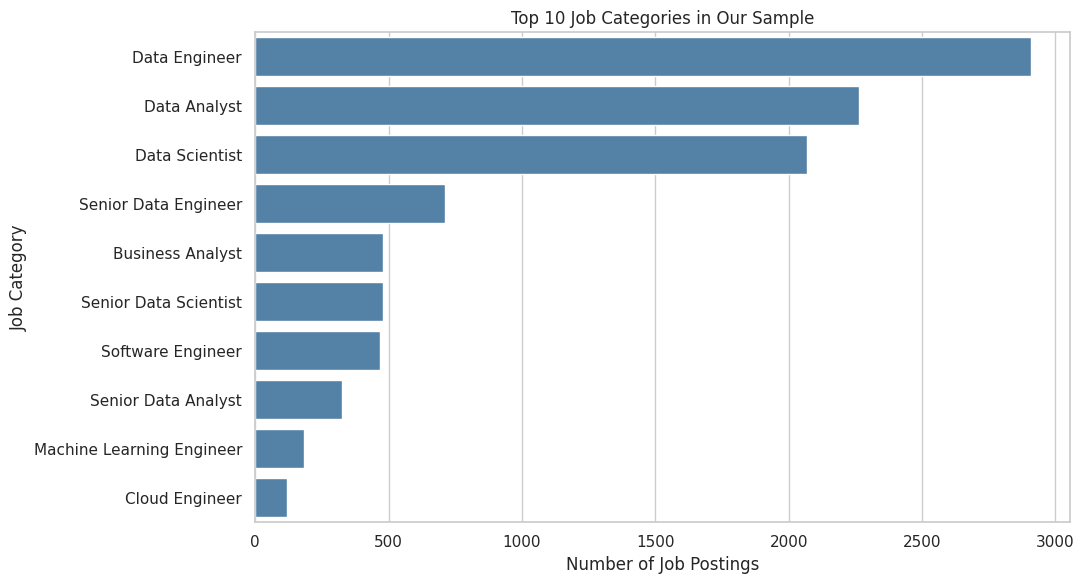

In [5]:

# Count postings by standardized job title
job_counts = (
    df["job_title_short"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_counts.values,
    y=job_counts.index,
    color="steelblue"
)

plt.title("Top 10 Job Categories in Our Sample")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


## Create a copy and convert dates

In [6]:

# Create a working copy
df_clean = df.copy()

# Convert posting date to datetime
df_clean["job_posted_date"] = pd.to_datetime(
    df_clean["job_posted_date"],
    errors="coerce"
)

# Convert salary columns to numeric
salary_columns = ["salary_year_avg", "salary_hour_avg"]

for col in salary_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Updated data types:")
print(df_clean[
    ["job_posted_date", "salary_year_avg", "salary_hour_avg"]
].dtypes)

print("\nInvalid dates:",
      df_clean["job_posted_date"].isna().sum())


Updated data types:
job_posted_date    datetime64[ns]
salary_year_avg           float64
salary_hour_avg           float64
dtype: object

Invalid dates: 0


## Handle Missing Values

In [7]:

# Fill missing categorical values
columns_to_fill = [
    "job_location",
    "job_country",
    "job_schedule_type",
    "job_via"
]

for col in columns_to_fill:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates().copy()

# Add a salary availability indicator
df_clean["has_annual_salary"] = (
    df_clean["salary_year_avg"].notna()
)

print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())


Cleaned dataset shape: (10000, 18)

Missing values after cleaning:


,0
job_title_short,0
job_title,0
job_location,0
job_via,0
job_schedule_type,0
job_work_from_home,0
search_location,0
job_posted_date,0
job_no_degree_mention,0
job_health_insurance,0


## Extract the Job Skills

In [8]:

import ast

def parse_skills(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return parsed
        except (ValueError, SyntaxError):
            pass

    return []

df_clean["skills_list"] = (
    df_clean["job_skills"].apply(parse_skills)
)

print("Example skills:")
display(
    df_clean[["job_title_short", "skills_list"]].head(10)
)

print(
    "Jobs with extracted skills:",
    df_clean["skills_list"].apply(len).gt(0).sum()
)


Example skills:


,job_title_short,skills_list
0,Senior Data Engineer,[]
1,Data Analyst,"[r, python, sql, nosql, power bi, tableau]"
2,Data Engineer,"[python, sql, c#, azure, airflow, dax, docker,..."
3,Data Engineer,"[python, c++, java, matlab, aws, tensorflow, k..."
4,Data Engineer,"[bash, python, oracle, aws, ansible, puppet, j..."
5,Data Engineer,"[python, sql, gcp]"
6,Senior Data Engineer,"[sql, python, java, sql server, gcp, bigquery,..."
7,Data Engineer,"[sql, nosql, gcp, azure, aws, bigquery, databr..."
8,Business Analyst,"[excel, powerpoint, power bi]"
9,Data Scientist,"[sql, python, r, mongodb, mongodb, sql server,..."


Jobs with extracted skills: 8756


## Create a Skills Frequency Table

In [9]:
# Count each normalized skill at most once per posting
skill_rows = df_clean.reset_index(drop=True).reset_index(names="job_id")[["job_id", "skills_list"]].explode("skills_list")
skill_rows = skill_rows.dropna(subset=["skills_list"])
skill_rows["skills_list"] = skill_rows["skills_list"].astype(str).str.strip().str.lower()
skill_rows = skill_rows[skill_rows["skills_list"] != ""].drop_duplicates(["job_id", "skills_list"])
skill_counts = skill_rows["skills_list"].value_counts().rename_axis("Skill").reset_index(name="Job Count")
display(skill_counts.head(20))

,Skill,Job Count
0,python,5357
1,sql,5288
2,aws,2181
3,azure,1895
4,r,1750
5,spark,1735
6,tableau,1594
7,excel,1414
8,java,1234
9,power bi,1216


## Visualize the Most Requested Skills

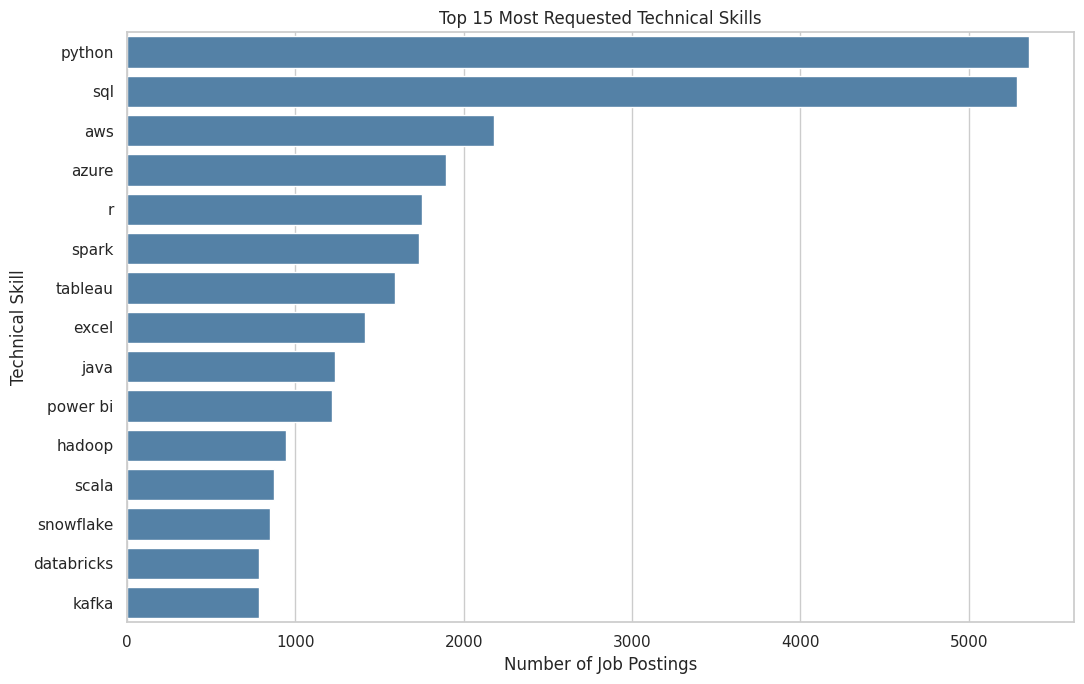

In [10]:

top_skills = skill_counts.head(15)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_skills,
    x="Job Count",
    y="Skill",
    color="steelblue"
)

plt.title("Top 15 Most Requested Technical Skills")
plt.xlabel("Number of Job Postings")
plt.ylabel("Technical Skill")

plt.tight_layout()
plt.show()


## Historical data — Skills by role

## Filter the Three main Job Categories

In [11]:

# Select the three job categories
selected_jobs = [
    "Data Analyst",
    "Data Engineer",
    "Data Scientist"
]

df_roles = df_clean[
    df_clean["job_title_short"].isin(selected_jobs)
].copy()

print("Job postings by category:")
display(df_roles["job_title_short"].value_counts())

print("\nTotal selected postings:", len(df_roles))


Job postings by category:


,count
job_title_short,
Data Engineer,2909
Data Analyst,2263
Data Scientist,2067



Total selected postings: 7239


## Calculate Skill Demand by Job Category

In [12]:
# Unique posting-level skill counts for three job categories
# df_roles was created in the preceding filter cell.
roles_with_id = df_roles.reset_index(drop=True).reset_index(names="job_id")
skills_by_role = (roles_with_id[["job_id", "job_title_short", "skills_list"]]
                  .explode("skills_list")
                  .dropna(subset=["skills_list"]))
skills_by_role["skills_list"] = skills_by_role["skills_list"].astype(str).str.strip().str.lower()
skills_by_role = skills_by_role[skills_by_role["skills_list"] != ""]
skills_by_role = skills_by_role.drop_duplicates(["job_id", "skills_list"])
role_totals = (roles_with_id[roles_with_id["skills_list"].apply(len).gt(0)]
               .groupby("job_title_short").size())
skill_role_counts = (skills_by_role.groupby(["job_title_short", "skills_list"])
                     .size().reset_index(name="count"))
skill_role_counts["percentage"] = (skill_role_counts["count"] /
    skill_role_counts["job_title_short"].map(role_totals) * 100)
print("Skill percentages use postings with nonempty skills as denominator.")
display(skill_role_counts.head(10))

Skill percentages use postings with nonempty skills as denominator.


,job_title_short,skills_list,count,percentage
0,Data Analyst,airflow,23,1.222754
1,Data Analyst,airtable,2,0.106326
2,Data Analyst,alteryx,46,2.445508
3,Data Analyst,angular,6,0.318979
4,Data Analyst,ansible,3,0.159490
5,Data Analyst,asana,4,0.212653
6,Data Analyst,asp.net,4,0.212653
7,Data Analyst,asp.net core,1,0.053163
8,Data Analyst,assembly,11,0.584795
9,Data Analyst,atlassian,2,0.106326


## Compare the Top 10 Skills for Each Role

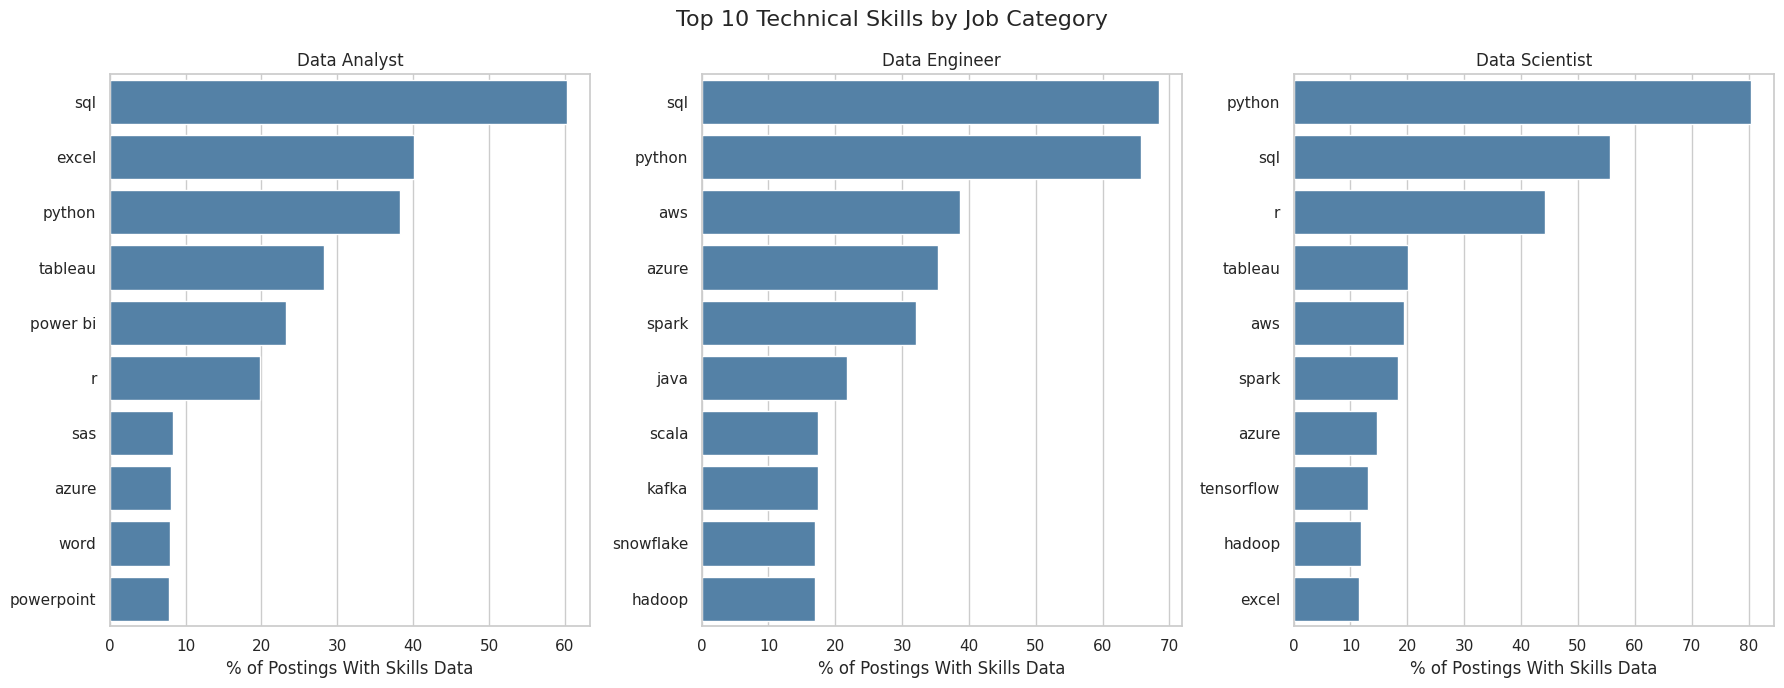

In [13]:

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, role in zip(axes, selected_jobs):

    role_data = (
        skill_role_counts[
            skill_role_counts["job_title_short"] == role
        ]
        .sort_values("percentage", ascending=False)
        .head(10)
    )

    sns.barplot(
        data=role_data,
        x="percentage",
        y="skills_list",
        ax=ax,
        color="steelblue"
    )

    ax.set_title(role)
    ax.set_xlabel("% of Postings With Skills Data")
    ax.set_ylabel("")

plt.suptitle(
    "Top 10 Technical Skills by Job Category",
    fontsize=16
)

plt.tight_layout()
plt.show()


## Create a Skills Comparison Heatmap

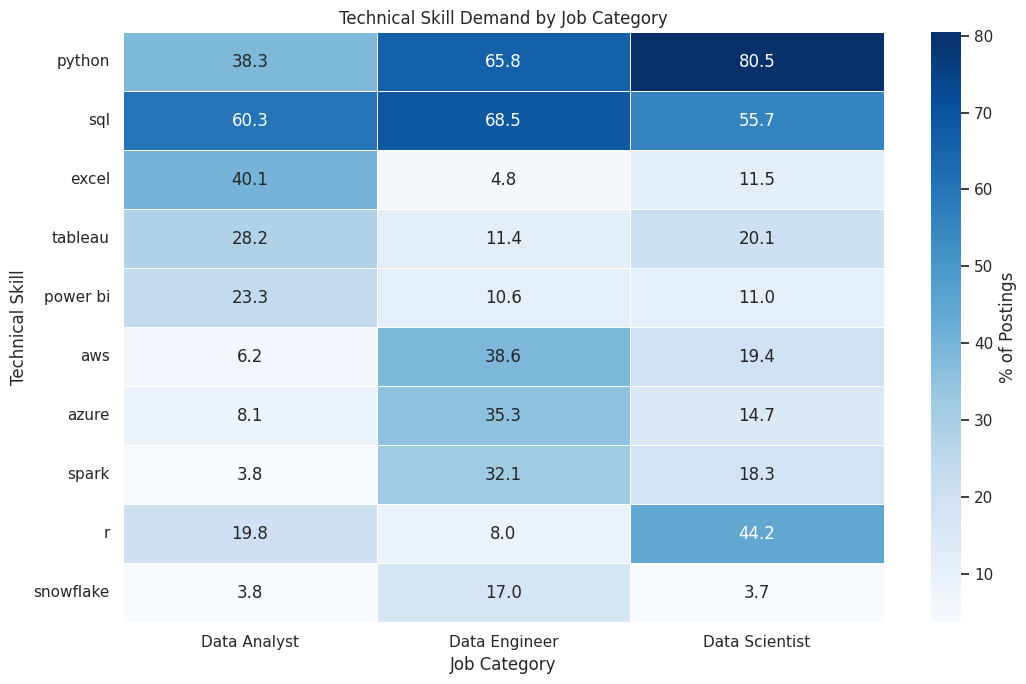

In [14]:

# Select skills for comparison
comparison_skills = [
    "python", "sql", "excel", "tableau",
    "power bi", "aws", "azure", "spark",
    "r", "snowflake"
]

heatmap_data = (
    skill_role_counts[
        skill_role_counts["skills_list"].isin(
            comparison_skills
        )
    ]
    .pivot(
        index="skills_list",
        columns="job_title_short",
        values="percentage"
    )
    .reindex(
        index=comparison_skills,
        columns=selected_jobs
    )
    .fillna(0)
)

plt.figure(figsize=(11, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "% of Postings"}
)

plt.title("Technical Skill Demand by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Technical Skill")

plt.tight_layout()
plt.show()


### Skill-analysis interpretation
SQL and Python appear prominently, but the mix differs by role: Data Analysts show relatively more Excel and visualization tools; Data Engineers show more cloud and infrastructure technologies; Data Scientists show more Python and R. Percentages in the role charts use postings with nonempty skills lists as the denominator, and count each skill once per posting.

## Historical data — Geography and remote work

## Top 15 Countries by Job Postings

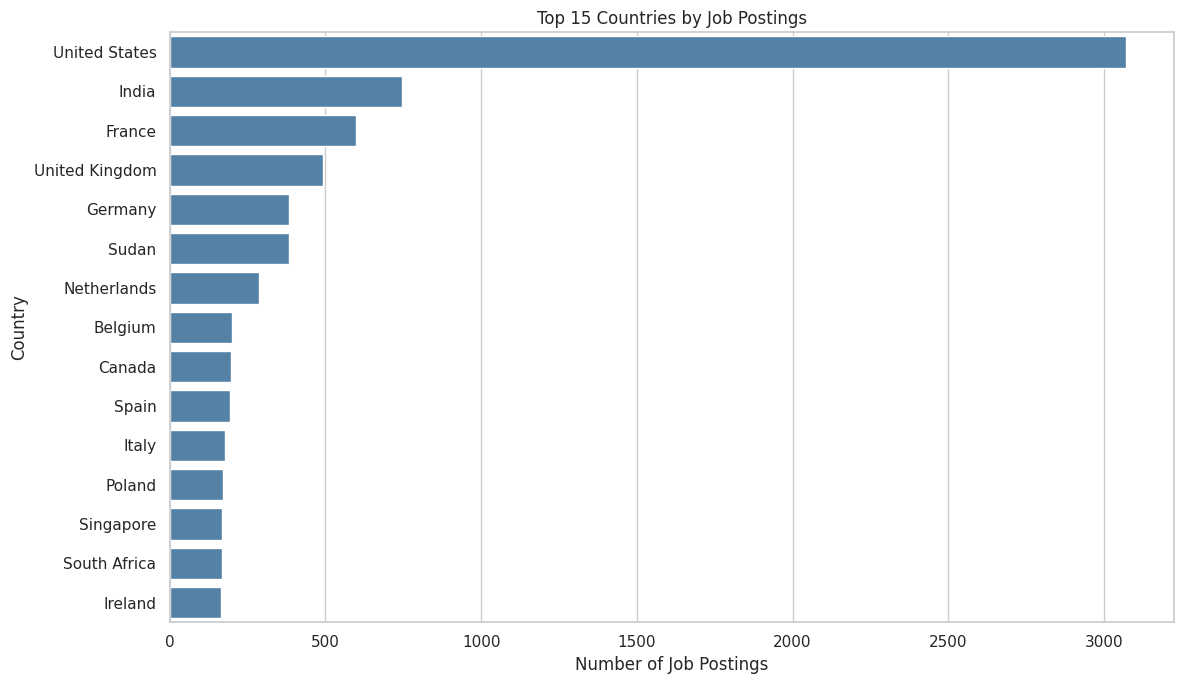

In [15]:

# Count postings by country
country_counts = (
    df_clean[
        df_clean["job_country"] != "Unknown"
    ]["job_country"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    color="steelblue"
)

plt.title("Top 15 Countries by Job Postings")
plt.xlabel("Number of Job Postings")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


## Analyze Remote-Work Opportunities

In [16]:
# Treat missing work-from-home flags as unknown rather than non-remote
remote_by_role = (df_clean.groupby("job_title_short")["job_work_from_home"]
                  .agg(total_jobs="count", remote_jobs="sum", remote_percentage="mean")
                  .reset_index())
remote_by_role["remote_percentage"] *= 100
remote_by_role = remote_by_role.sort_values("remote_percentage", ascending=False)
display(remote_by_role)

,job_title_short,total_jobs,remote_jobs,remote_percentage
7,Senior Data Engineer,711,127,17.862166
3,Data Engineer,2909,448,15.400481
8,Senior Data Scientist,479,68,14.196242
9,Software Engineer,468,56,11.965812
4,Data Scientist,2067,245,11.852927
5,Machine Learning Engineer,182,20,10.989011
2,Data Analyst,2263,218,9.633230
6,Senior Data Analyst,324,30,9.259259
0,Business Analyst,479,35,7.306889
1,Cloud Engineer,118,6,5.084746


## Visualize Remote-Work Percentages

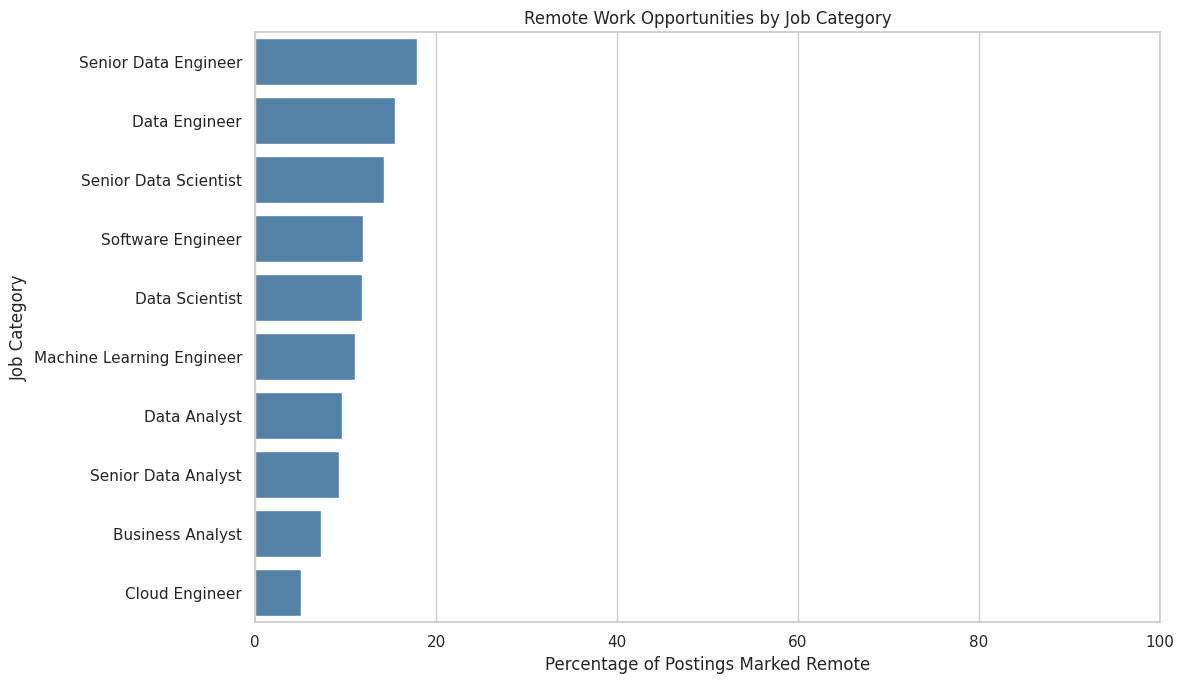

In [17]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=remote_by_role,
    x="remote_percentage",
    y="job_title_short",
    color="steelblue"
)

plt.title("Remote Work Opportunities by Job Category")
plt.xlabel("Percentage of Postings Marked Remote")
plt.ylabel("Job Category")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()


## Compare Remote and Non-Remote Jobs

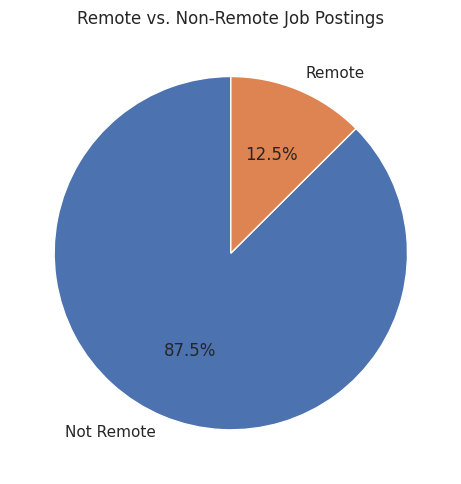

In [18]:

remote_counts = (
    df_clean["job_work_from_home"]
    .value_counts()
    .rename(index={
        True: "Remote",
        False: "Not Remote"
    })
)

plt.figure(figsize=(7, 5))

plt.pie(
    remote_counts.values,
    labels=remote_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Remote vs. Non-Remote Job Postings")
plt.tight_layout()
plt.show()


### Geography and remote-work interpretation
The United States has the largest number of postings **in this convenience slice**. Country counts may reflect how the source was collected, rather than worldwide job demand. The `job_work_from_home` flag identifies postings marked work-from-home; it is not a complete measure of hybrid arrangements. Percentages are descriptive for the sampled postings.

## Historical data — Salary analysis

## Prepare the Salary Dataset

In [19]:

# Keep postings with reported annual salaries
df_salary = df_clean[
    df_clean["salary_year_avg"].notna()
].copy()

# Remove invalid salary values
df_salary = df_salary[
    df_salary["salary_year_avg"] > 0
]

print("Total postings:", len(df_clean))
print("Postings with valid annual salary:", len(df_salary))

print("\nSalary summary:")
display(
    df_salary["salary_year_avg"].describe()
)

print("\nSalary records by job category:")
display(
    df_salary["job_title_short"].value_counts()
)


Total postings: 10000
Postings with valid annual salary: 344

Salary summary:


,salary_year_avg
count,344.000000
mean,132161.194415
std,50776.175085
min,30750.000000
25%,99787.500000
50%,127500.000000
75%,158125.000000
max,375000.000000



Salary records by job category:


,count
job_title_short,
Data Engineer,112
Data Scientist,73
Data Analyst,60
Senior Data Engineer,45
Senior Data Scientist,22
Senior Data Analyst,11
Business Analyst,10
Software Engineer,6
Machine Learning Engineer,5


## Compare Median Annual salaries by Role

In [20]:

salary_by_role = (
    df_salary
    .groupby("job_title_short")
    .agg(
        median_salary=("salary_year_avg", "median"),
        mean_salary=("salary_year_avg", "mean"),
        job_count=("salary_year_avg", "count")
    )
    .reset_index()
)

# Only display categories with at least 10 salary records
salary_by_role = salary_by_role[
    salary_by_role["job_count"] >= 10
].sort_values(
    "median_salary",
    ascending=False
)

display(salary_by_role)


,job_title_short,median_salary,mean_salary,job_count
7,Senior Data Scientist,156250.0,150005.386364,22
6,Senior Data Engineer,147500.0,150025.466667,45
2,Data Engineer,137500.0,139495.281738,112
3,Data Scientist,136400.0,142407.130137,73
5,Senior Data Analyst,111175.0,118775.500000,11
1,Data Analyst,90125.0,94446.397070,60
0,Business Analyst,86250.0,85630.000000,10


## Visualize Median Salaries

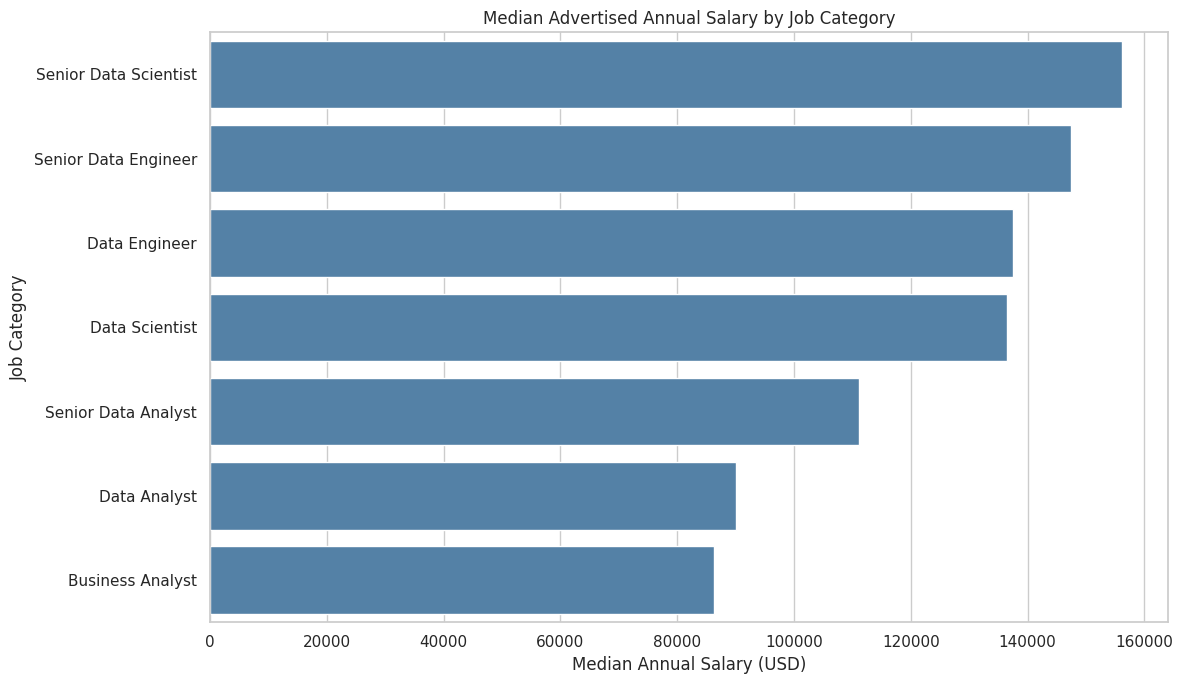

In [21]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=salary_by_role,
    x="median_salary",
    y="job_title_short",
    color="steelblue"
)

plt.title("Median Advertised Annual Salary by Job Category")
plt.xlabel("Median Annual Salary (USD)")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()


## Check Salary Differences by Country

In [22]:

salary_countries = (
    df_salary["job_country"]
    .value_counts()
    .head(15)
)

print("Countries with reported annual salaries:")
display(salary_countries)

# Check salary reporting rate by country
salary_reporting = (
    df_clean.groupby("job_country")
    .agg(
        total_jobs=("salary_year_avg", "size"),
        jobs_with_salary=("salary_year_avg", "count")
    )
)

salary_reporting["reporting_rate"] = (
    salary_reporting["jobs_with_salary"] /
    salary_reporting["total_jobs"] * 100
)

display(
    salary_reporting.sort_values(
        "jobs_with_salary",
        ascending=False
    ).head(15)
)


Countries with reported annual salaries:


,count
job_country,
United States,254
Sudan,34
India,8
Israel,4
United Kingdom,4
Estonia,2
Denmark,2
Germany,2
Sweden,2


,total_jobs,jobs_with_salary,reporting_rate
job_country,,,
United States,3071,254,8.270922
Sudan,382,34,8.900524
India,747,8,1.070950
United Kingdom,491,4,0.814664
Israel,108,4,3.703704
Estonia,15,2,13.333333
Malaysia,114,2,1.754386
Denmark,113,2,1.769912
Canada,198,2,1.010101


## Create a US-only Salary Dataset

In [23]:

# Filter for US jobs with valid annual salary data
df_us_salary = df_clean[
    (df_clean["job_country"] == "United States") &
    (df_clean["salary_year_avg"].notna()) &
    (df_clean["salary_year_avg"] > 0)
].copy()

print("US postings with annual salaries:", len(df_us_salary))

us_salary_summary = (
    df_us_salary
    .groupby("job_title_short")
    .agg(
        median_salary=("salary_year_avg", "median"),
        mean_salary=("salary_year_avg", "mean"),
        job_count=("salary_year_avg", "count")
    )
    .reset_index()
)

display(
    us_salary_summary.sort_values(
        "median_salary", ascending=False
    )
)


US postings with annual salaries: 254


,job_title_short,median_salary,mean_salary,job_count
7,Software Engineer,275250.0,275250.000000,2
6,Senior Data Scientist,152500.0,149130.925000,20
5,Senior Data Engineer,151250.0,159542.000000,30
3,Data Scientist,138640.0,147862.442623,61
2,Data Engineer,137000.0,137888.679688,81
4,Senior Data Analyst,102500.0,119535.550000,10
1,Data Analyst,99150.0,101566.484983,45
0,Business Analyst,90000.0,98500.000000,5


## Visualize US Median Salaries

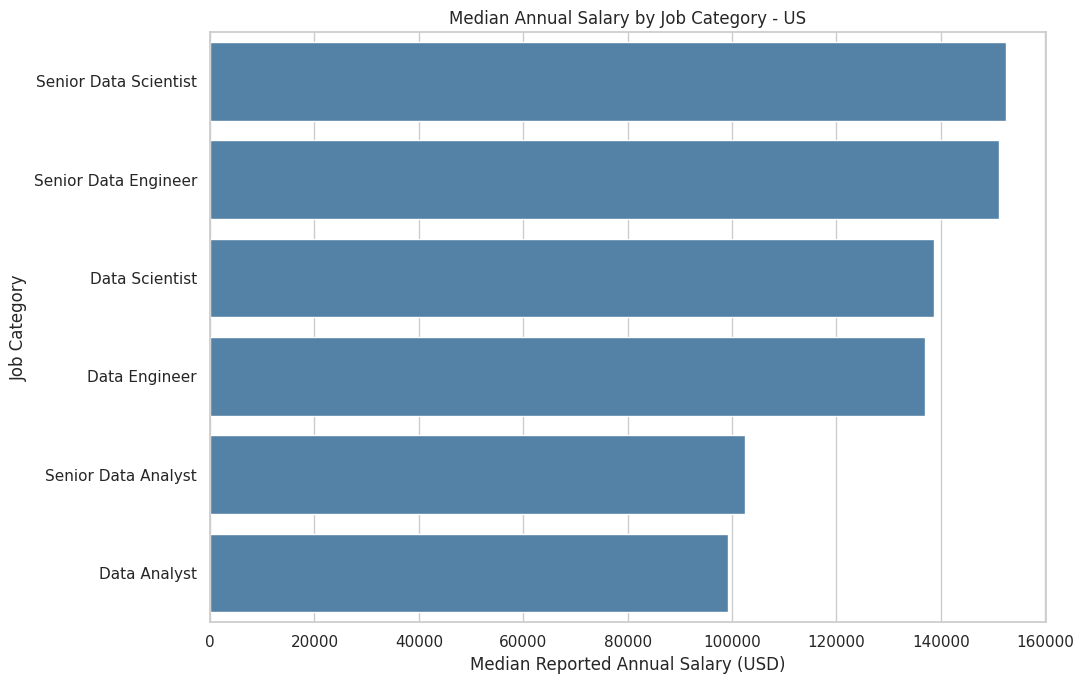

In [24]:

us_salary_plot = (
    us_salary_summary[
        us_salary_summary["job_count"] >= 10
    ]
    .sort_values("median_salary", ascending=False)
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=us_salary_plot,
    x="median_salary",
    y="job_title_short",
    color="steelblue"
)

plt.title("Median Annual Salary by Job Category - US")
plt.xlabel("Median Reported Annual Salary (USD)")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()


## Export our Analysis to Excel

## Additional data collection — Remotive remote-jobs API
This optional API snapshot is **not directly comparable** to the historical data-jobs dataset. It covers remote jobs in multiple occupations, and results may change or be unavailable.

### Retrieve Live Job Postings

In [25]:
import requests
from bs4 import BeautifulSoup
try:
    response = requests.get("https://remotive.com/api/remote-jobs", params={"limit": 100}, timeout=30)
    response.raise_for_status()
    jobs = response.json().get("jobs", [])
except requests.RequestException as exc:
    print("Remotive API unavailable; continuing with an empty live snapshot:", exc)
    jobs = []
df_live = pd.DataFrame(jobs)
for col in ["id", "title", "company_name", "candidate_required_location", "publication_date", "description"]:
    if col not in df_live.columns: df_live[col] = pd.Series(dtype="object")
print("Jobs retrieved:", len(df_live))
display(df_live.head())

Jobs retrieved: 12


,id,url,title,company_name,company_logo,category,tags,job_type,publication_date,candidate_required_location,salary,description,company_logo_url
0,2091168,https://remotive.com/remote-jobs/customer-serv...,US Remote Patient Care Advocate (Customer Serv...,VXI Global Solutions,https://remotive.com/job/2091168/logo,Customer Service,"[healthcare, insurance]",full_time,2026-11-06T08:51:01,USA,$25k - $35k,"<p style=""margin: 0px; padding: 0px; border-st...",https://remotive.com/job/2091168/logo
1,1185979,https://remotive.com/remote-jobs/writing/freel...,Freelance Writer,IAPWE,https://remotive.com/job/1185979/logo,Writing,[REST],freelance,2026-11-04T16:53:35,Worldwide,$50-$75 /hour,"<p class=""p1"" style=""font-variant-numeric: nor...",https://remotive.com/job/1185979/logo
2,2091166,https://remotive.com/remote-jobs/all-others/co...,Content Reviewer - United States,TELUS Digital,https://remotive.com/job/2091166/logo,All others,"[android, ios, social media, AI/ML]",part_time,2026-11-04T13:39:06,USA,$14/hour,"<p class=""figma-padding-bottom-32 tw-border-b ...",https://remotive.com/job/2091166/logo
3,1749306,https://remotive.com/remote-jobs/writing/freel...,Freelance Copywriter,Coalition Technologies,https://remotive.com/job/1749306/logo,Writing,"[accounting, excel, research, data analysis, b...",freelance,2026-11-02T20:01:00,Worldwide,$20k -$35k,<p>CT Marketing Agency is seeking skilled Free...,https://remotive.com/job/1749306/logo
4,2091165,https://remotive.com/remote-jobs/software-deve...,Full-Stack Developer,"Fluence International, Inc.",https://remotive.com/job/2091165/logo,Software Development,"[admin, api, AWS, backend, cloud, docker, fron...",contract,2026-10-29T18:22:41,Worldwide,$3.5k–$5k/month,"<p dir=""ltr"" style=""line-height: 1.38000000000...",NaN


### Clean the Live Dataset

In [26]:

# Convert HTML descriptions to readable text
def clean_html(html):
    if not isinstance(html, str):
        return ""

    soup = BeautifulSoup(html, "html.parser")
    return soup.get_text(" ", strip=True)

df_live["description_clean"] = (
    df_live["description"].apply(clean_html)
)

# Convert publication dates
df_live["publication_date"] = pd.to_datetime(
    df_live["publication_date"],
    errors="coerce",
    utc=True
)

# Remove duplicate job IDs
df_live = df_live.drop_duplicates(
    subset=["id"]
).copy()

print("Cleaned live postings:", len(df_live))

display(
    df_live[
        ["title", "company_name",
         "candidate_required_location",
         "publication_date"]
    ].head(10)
)


Cleaned live postings: 12


,title,company_name,candidate_required_location,publication_date
0,US Remote Patient Care Advocate (Customer Serv...,VXI Global Solutions,USA,2026-11-06 08:51:01+00:00
1,Freelance Writer,IAPWE,Worldwide,2026-11-04 16:53:35+00:00
2,Content Reviewer - United States,TELUS Digital,USA,2026-11-04 13:39:06+00:00
3,Freelance Copywriter,Coalition Technologies,Worldwide,2026-11-02 20:01:00+00:00
4,Full-Stack Developer,"Fluence International, Inc.",Worldwide,2026-10-29 18:22:41+00:00
5,Senior Back-end Developer,Lemon.io,"Europe, USA, Canada, Australia, Singapore, Mex...",2026-10-27 12:56:13+00:00
6,Head of Engineering,Lemon.io,Worldwide,2026-10-26 12:20:09+00:00
7,AI Trainer - Video Annotation,iMerit Technology,Worldwide,2026-10-22 18:40:19+00:00
8,"Software Engineer, AI Coding Tasks",Askable,Worldwide,2026-10-17 16:04:29+00:00
9,Tech Lead Full-Stack Rails Engineer,Mitre Media,"USA, Canada, USA timezones",2026-10-14 20:33:44+00:00


### Extract Technical Skills from Descriptions

In [27]:

import re

skills_to_find = [
    "python", "sql", "excel", "tableau",
    "power bi", "aws", "azure", "spark",
    "snowflake", "r", "pandas", "numpy"
]

def extract_skills(text):
    text = str(text).lower()
    found = []

    for skill in skills_to_find:
        pattern = r"(?<!\w)" + re.escape(skill) + r"(?!\w)"

        if re.search(pattern, text):
            found.append(skill)

    return found

df_live["extracted_skills"] = (
    df_live["description_clean"].apply(extract_skills)
)

display(
    df_live[["title", "extracted_skills"]].head(15)
)


,title,extracted_skills
0,US Remote Patient Care Advocate (Customer Serv...,[]
1,Freelance Writer,[]
2,Content Reviewer - United States,[]
3,Freelance Copywriter,[]
4,Full-Stack Developer,[aws]
5,Senior Back-end Developer,[python]
6,Head of Engineering,[]
7,AI Trainer - Video Annotation,[]
8,"Software Engineer, AI Coding Tasks",[python]
9,Tech Lead Full-Stack Rails Engineer,[]


### Analyze the Live Skill Counts

,Skill,Job Count
0,python,2
1,aws,1
2,excel,1


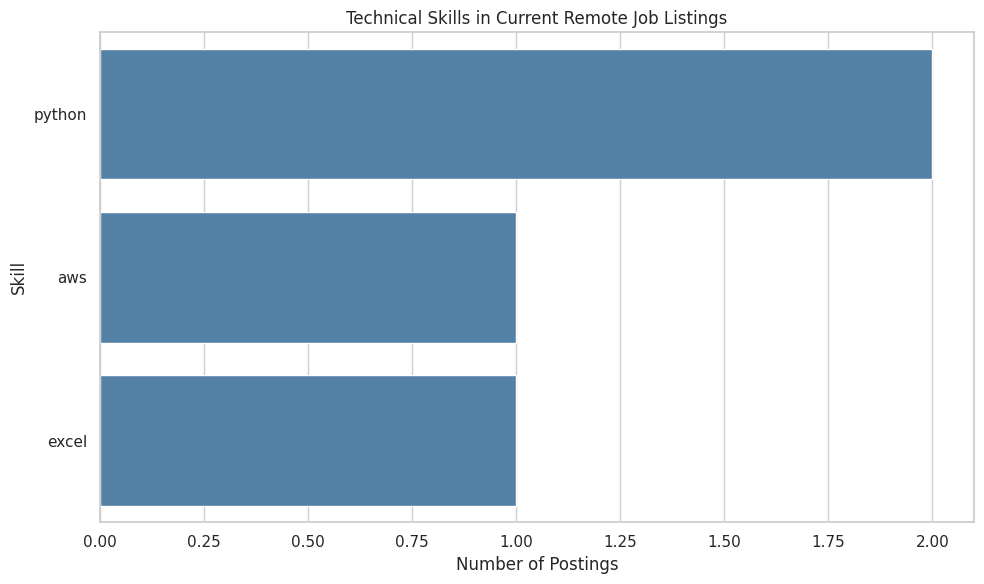

In [28]:

live_skills = (
    df_live["extracted_skills"]
    .explode()
    .dropna()
    .value_counts()
    .reset_index()
)

live_skills.columns = ["Skill", "Job Count"]

display(live_skills)

if not live_skills.empty:
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=live_skills.head(10),
        x="Job Count",
        y="Skill",
        color="steelblue"
    )

    plt.title("Technical Skills in Current Remote Job Listings")
    plt.xlabel("Number of Postings")
    plt.ylabel("Skill")

    plt.tight_layout()
    plt.show()
else:
    print("No matching skills found in this sample.")


### Add the Live Data to our Excel Workbook

# Part 2: Machine Learning — Salary Prediction

## Dataset Introduction

**Dataset:** Data Science Salaries 2023

**Source:** Kaggle — arnabchaki/data-science-salaries-2023

**Purpose:** This dataset contains salary information
for professionals working in data science and related
technology roles.

### Key Variables

- work_year: Year the salary was paid
- experience_level: Employee experience category
- employment_type: Full-time, part-time, contract, etc.
- job_title: Job position
- salary_in_usd: Annual salary expressed in USD
- employee_residence: Employee's country of residence
- remote_ratio: Percentage of work performed remotely
- company_location: Employer's country
- company_size: Company size category

### Machine Learning Objective

Build a regression model to predict annual salaries
using job characteristics.

We will compare a baseline prediction against a
Random Forest Regression model.

Model performance will be evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)


**Data-quality policy:** Exact duplicate rows are removed before splitting for this modeling exercise. Because employee identifiers are unavailable, identical rows could sometimes represent distinct real observations.

In [29]:
# Upload the Kaggle CSV when running in a fresh Colab session.
# If already present in /content, no upload is required.
from pathlib import Path
csv_candidates = sorted(Path("/content").glob("ds_salaries*.csv"))
if not csv_candidates:
    from google.colab import files
    print("Upload ds_salaries.csv from the Kaggle dataset.")
    uploaded = files.upload()
    csv_candidates = [Path(name) for name in uploaded if name.lower().endswith(".csv")]
if not csv_candidates:
    raise FileNotFoundError("Please upload the Kaggle ds_salaries.csv file.")
df_kaggle = pd.read_csv(csv_candidates[0])
print("Kaggle dataset shape:", df_kaggle.shape)
display(df_kaggle.head())

Upload ds_salaries.csv from the Kaggle dataset.


Saving ds_salaries.csv to ds_salaries.csv
Kaggle dataset shape: (3755, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


### Inspect and clean Kaggle salary records

In [30]:
print("Original shape:", df_kaggle.shape)
print("Missing values:")
display(df_kaggle.isna().sum().to_frame("missing"))
print("Exact duplicate rows:", df_kaggle.duplicated().sum())
print("Nonpositive / missing USD salary:", ((df_kaggle["salary_in_usd"] <= 0) | df_kaggle["salary_in_usd"].isna()).sum())
display(df_kaggle["salary_in_usd"].describe())
for col in ["work_year", "experience_level", "employment_type", "remote_ratio", "company_size"]:
    print("\n", col)
    display(df_kaggle[col].value_counts(dropna=False))
# Conservative modeling choice: exclude invalid salary rows, then exact duplicates
df_ml_clean = (df_kaggle.loc[df_kaggle["salary_in_usd"].notna() &
                             df_kaggle["salary_in_usd"].gt(0)]
               .drop_duplicates().copy())
print("Rows after quality checks:", len(df_ml_clean))

Original shape: (3755, 11)
Missing values:


,missing
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


Exact duplicate rows: 1171
Nonpositive / missing USD salary: 0


,salary_in_usd
count,3755.000000
mean,137570.389880
std,63055.625278
min,5132.000000
25%,95000.000000
50%,135000.000000
75%,175000.000000
max,450000.000000



 work_year


,count
work_year,
2023,1785
2022,1664
2021,230
2020,76


... (5 outputs left out)

,count
remote_ratio,
0,1923
100,1643
50,189



 company_size


,count
company_size,
M,3153
L,454
S,148


Rows after quality checks: 2584


### Features, holdout split, preprocessing, and baseline

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

feature_columns = ["work_year", "experience_level", "employment_type", "job_title",
                   "employee_residence", "remote_ratio", "company_location", "company_size"]
categorical_features = ["experience_level", "employment_type", "job_title",
                        "employee_residence", "company_location", "company_size"]
numeric_features = ["work_year", "remote_ratio"]
# Exclude salary and salary_currency: both would leak target information.
X_clean = df_ml_clean[feature_columns].copy()
y_clean = df_ml_clean["salary_in_usd"].copy()
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean, test_size=0.20, random_state=42)
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", "passthrough", numeric_features)
])
rf_model_clean = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42,
                                        min_samples_leaf=3, n_jobs=-1))
])
print("Train/test rows:", len(X_train_clean), len(X_test_clean))

Train/test rows: 2067 517


### Train and evaluate Random Forest against a median baseline

In [32]:
rf_model_clean.fit(X_train_clean, y_train_clean)
y_pred_clean = rf_model_clean.predict(X_test_clean)
baseline_pred_clean = np.full(len(y_test_clean), y_train_clean.median())
def evaluate_model(name, actual, predicted):
    return {"Model": name,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R²": r2_score(actual, predicted)}
results_clean = pd.DataFrame([
    evaluate_model("Baseline (median)", y_test_clean, baseline_pred_clean),
    evaluate_model("Random Forest (deduplicated)", y_test_clean, y_pred_clean)
])
display(results_clean.round(2))
base_mae, rf_mae = results_clean["MAE"].iloc[0], results_clean["MAE"].iloc[1]
print(f"MAE improvement vs median baseline: {(base_mae-rf_mae)/base_mae*100:.2f}%")

,Model,MAE,RMSE,R²
0,Baseline (median),53555.26,66194.56,-0.00
1,Random Forest (deduplicated),39733.24,52991.55,0.36


MAE improvement vs median baseline: 25.81%


### Visualize test predictions

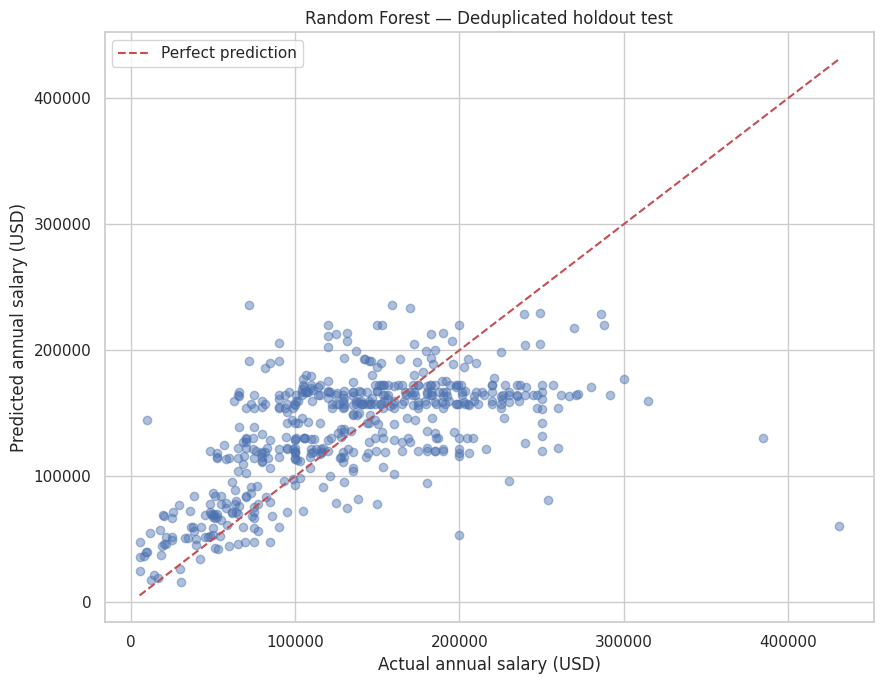

In [33]:
plt.figure(figsize=(9, 7))
plt.scatter(y_test_clean, y_pred_clean, alpha=.45)
lo = min(y_test_clean.min(), y_pred_clean.min())
hi = max(y_test_clean.max(), y_pred_clean.max())
plt.plot([lo,hi],[lo,hi], "r--", label="Perfect prediction")
plt.xlabel("Actual annual salary (USD)")
plt.ylabel("Predicted annual salary (USD)")
plt.title("Random Forest — Deduplicated holdout test")
plt.legend(); plt.tight_layout(); plt.show()

### Interpret the cleaned model (impurity-based feature importance)

,Feature,Importance
166,cat__employee_residence_US,0.447602
33,cat__job_title_Data Analyst,0.087271
3,cat__experience_level_SE,0.061948
240,num__work_year,0.043629
0,cat__experience_level_EN,0.039970
241,num__remote_ratio,0.039070
2,cat__experience_level_MI,0.024146
105,cat__employee_residence_CA,0.023957
1,cat__experience_level_EX,0.020941
41,cat__job_title_Data Engineer,0.016719


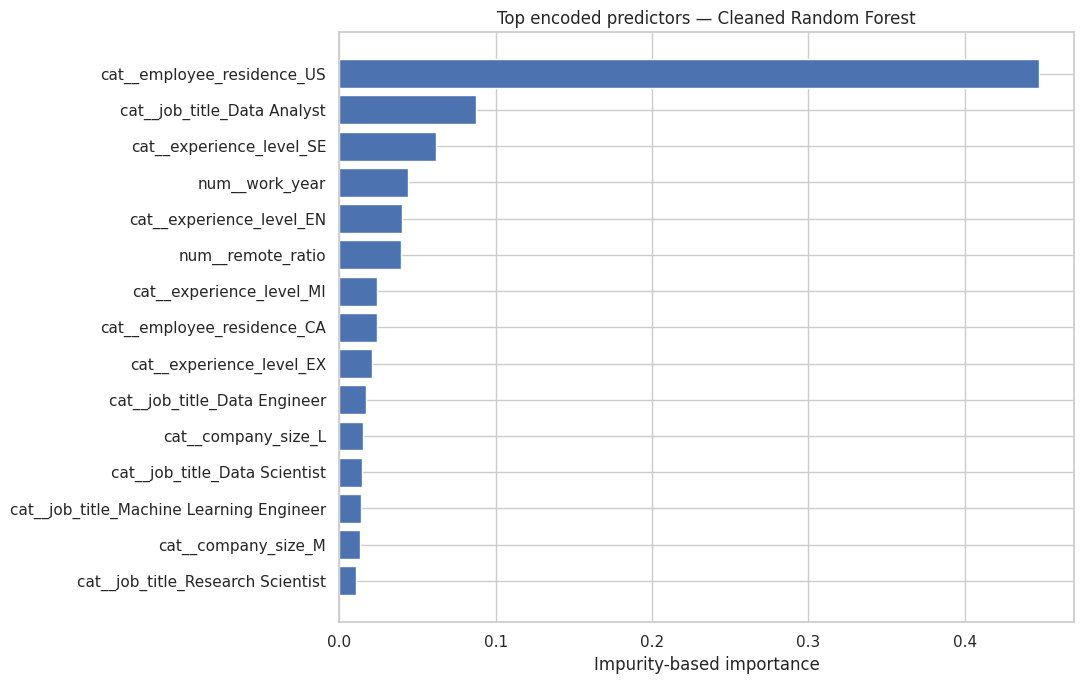

,Feature,Importance
4,employee_residence,0.490990
3,job_title,0.209134
1,experience_level,0.147005
0,work_year,0.043629
5,remote_ratio,0.039070
7,company_size,0.035966
6,company_location,0.033154
2,employment_type,0.001052


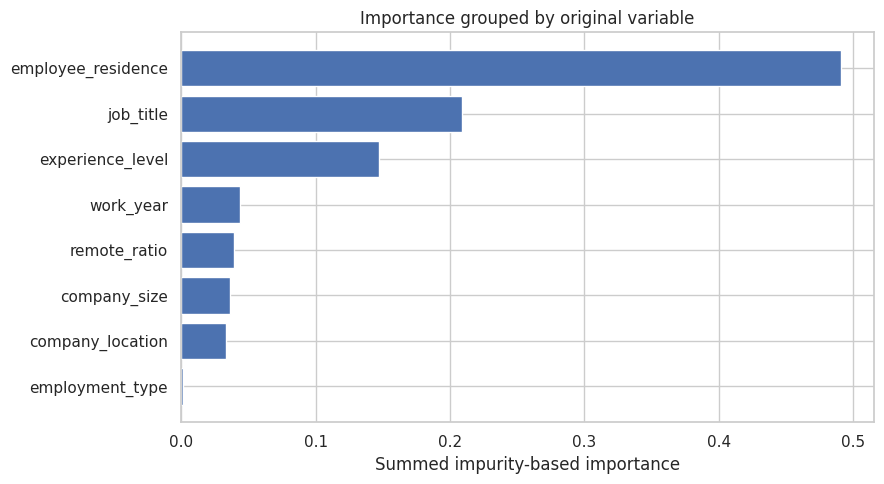

In [34]:
names = rf_model_clean.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model_clean.named_steps["regressor"].feature_importances_
feature_importance_clean = pd.DataFrame({"Feature": names, "Importance": importances})
feature_importance_clean = feature_importance_clean.sort_values("Importance", ascending=False)
display(feature_importance_clean.head(15))
plt.figure(figsize=(11, 7))
plt.barh(feature_importance_clean.head(15)["Feature"][::-1],
         feature_importance_clean.head(15)["Importance"][::-1])
plt.xlabel("Impurity-based importance")
plt.title("Top encoded predictors — Cleaned Random Forest")
plt.tight_layout(); plt.show()
# Aggregate encoded features to original variables (descriptive, not causal)
grouped_importance = []
for feature in feature_columns:
    if feature in numeric_features:
        mask = feature_importance_clean["Feature"].eq("num__" + feature)
    else:
        mask = feature_importance_clean["Feature"].str.startswith("cat__" + feature + "_")
    grouped_importance.append({"Feature": feature,
                               "Importance": feature_importance_clean.loc[mask,"Importance"].sum()})
grouped_importance = pd.DataFrame(grouped_importance).sort_values("Importance", ascending=False)
display(grouped_importance)
plt.figure(figsize=(9,5))
plt.barh(grouped_importance["Feature"][::-1], grouped_importance["Importance"][::-1])
plt.title("Importance grouped by original variable")
plt.xlabel("Summed impurity-based importance")
plt.tight_layout(); plt.show()

### Model interpretation and limitations
In the previous run of this project, the deduplicated model achieved approximately **MAE $39,733, RMSE $52,992, and R² 0.36**, improving MAE by **25.81%** relative to a median baseline. **The output above is authoritative for any new run**; these historical values may differ after rerunning or if the data change.

Salary prediction remains imprecise, especially at the extremes. Removing exact duplicates avoids identical full rows crossing the split, but may also remove legitimate separate observations. A random split is not a prospective evaluation on future years. Impurity-based importance can favor high-cardinality predictors and does not imply causation. This model is an educational proof of concept, not a salary quotation tool.

## Export datasets and analysis results

In [7]:
output_file = "Hackathon_Job_Market_Analysis.xlsx"
df_export = df_clean.copy()
df_export["skills_list"] = df_export["skills_list"].apply(lambda x: ", ".join(map(str, x)))

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df_export.to_excel(writer, sheet_name="Cleaned Historical Data", index=False)
    skill_counts.to_excel(writer, sheet_name="Skill Frequency", index=False)
    skill_role_counts.to_excel(writer, sheet_name="Skills by Role", index=False)
    remote_by_role.to_excel(writer, sheet_name="Remote Work", index=False)
    us_salary_summary.to_excel(writer, sheet_name="US Salaries", index=False)
    salary_reporting.reset_index().to_excel(writer, sheet_name="Salary Coverage", index=False)

    if 'df_ml_clean' in globals():
        df_ml_clean.to_excel(writer, sheet_name="Kaggle Cleaned Salaries", index=False)
    if 'results_clean' in globals():
        results_clean.to_excel(writer, sheet_name="ML Evaluation", index=False)
    if 'grouped_importance' in globals():
        grouped_importance.to_excel(writer, sheet_name="ML Feature Importance", index=False)

    if not df_live.empty:
        live_export = df_live.copy()
        if "publication_date" in live_export.columns and live_export["publication_date"].dt.tz is not None:
            live_export["publication_date"] = live_export["publication_date"].dt.tz_localize(None)
        if "extracted_skills" in live_export.columns:
            live_export["extracted_skills"] = live_export["extracted_skills"].apply(lambda x: ", ".join(x) if isinstance(x, list) else "")
        live_export = live_export.drop(columns=["description"], errors="ignore")
        live_export.to_excel(writer, sheet_name="Live Job Postings", index=False)
        live_skills.to_excel(writer, sheet_name="Live Skill Counts", index=False)

print("Workbook successfully created:", output_file)
df_export.to_csv("cleaned_job_market_data.csv", index=False)
print("CSV successfully created: cleaned_job_market_data.csv")

Workbook successfully created: Hackathon_Job_Market_Analysis.xlsx
CSV successfully created: cleaned_job_market_data.csv


## Final conclusions
1. **Skills vary by role.** Python and SQL are common; Analysts emphasize SQL, Excel and visualization; Engineers emphasize Python, SQL and cloud tools; Scientists emphasize Python and statistical programming.
2. **Geographic and remote patterns are sample-dependent.** Country counts and remote flags describe this historical convenience sample, not the global labor market.
3. **Salary reporting is sparse in historical postings.** US-only median comparisons reduce one source of geographic mixing but still rely on a small, selected set of postings.
4. **Machine learning adds a testable prediction question.** The deduplicated Random Forest outperformed a median baseline in the previous run, but its error remains substantial. Refer to the evaluation table above for the current run's metrics.
5. **Data quality changes the interpretation.** Exact duplicates were identified before modeling and removed as a documented choice, rather than silently ignored.

### Download deliverables


In [8]:
from google.colab import files
files.download("Hackathon_Job_Market_Analysis.xlsx")
files.download("cleaned_job_market_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>